# Лабораторная работа №2. Генерация ответа в диалоге

Цель: сравнить две архитектуры генеративных моделей — decoder-only (`DistilGPT2`) и encoder-decoder (`FLAN-T5-small`) — на парах реплик из DailyDialog. Сравниваются исходные и дообученные модели по BLEU и METEOR.

## Порядок работы

1. Из диалогов строим пары «сообщение → ответ».
2. Формируем входы отдельно для GPT-подобной и T5-подобной архитектур.
3. Сначала измеряем zero-shot качество.
4. Дообучаем обе модели одинаковое число эпох.
5. Генерируем ответы жадным декодированием и сравниваем BLEU/METEOR.

Для установки зависимостей выполните `%pip install -r requirements.txt`. Подробные пояснения находятся в `REPORT.md`.

## 1. Настройка путей и кэшей

In [7]:
from pathlib import Path
import os


def find_lab_root(lab_name: str) -> Path:
    current = Path.cwd().resolve()
    if current.name == lab_name:
        return current
    candidate = current / lab_name
    if candidate.exists():
        return candidate
    raise FileNotFoundError(
        f"Не найдена папка {lab_name}. Откройте ноутбук из корня проекта или из папки лабораторной."
    )


LAB_ROOT = find_lab_root("lab_2")
PROJECT_ROOT = LAB_ROOT.parent

# Кэши и временные файлы остаются на диске с проектом.
os.environ["HF_HOME"] = str(LAB_ROOT / ".cache" / "huggingface")
os.environ["HF_DATASETS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "datasets")
os.environ["TRANSFORMERS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "hub")
os.environ["TMP"] = str(LAB_ROOT / ".tmp")
os.environ["TEMP"] = str(LAB_ROOT / ".tmp")
os.environ["NLTK_DATA"] = str(LAB_ROOT / ".cache" / "nltk_data")

print(f"Папка лабораторной: {LAB_ROOT}")

Папка лабораторной: G:\ITMO\LLM_2026\lab_2


## 2. Подготовка диалоговых пар и датасетов

In [8]:

import random
import re
from dataclasses import dataclass
from typing import Any

import torch
from datasets import load_dataset
from torch.utils.data import Dataset


DATASET_NAME = "OpenRL/daily_dialog"


@dataclass(frozen=True)
class DialoguePair:
    message: str
    response: str


def _clean(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()


def load_dialogue_pairs(split: str, limit: int | None, seed: int) -> tuple[list[DialoguePair], dict[str, Any]]:
    """Преобразует диалоги в соседние пары «сообщение — ответ».

    В DailyDialog реплики упорядочены, но имена говорящих не указаны. Поскольку
    собеседники чередуются, соседние реплики можно считать одной обучающей парой:
    utterance[i] — входное сообщение, utterance[i + 1] — ответ на него.
    """
    raw_split = load_dataset(DATASET_NAME, split=split)
    pairs: list[DialoguePair] = []

    for row in raw_split:
        # В parquet используется dialog, а в старых версиях датасета — utterances.
        dialogue = row.get("dialog", row.get("utterances"))
        if dialogue is None:
            raise KeyError("В DailyDialog не найдена колонка 'dialog' или 'utterances'")
        utterances = [_clean(value) for value in dialogue]
        for index in range(len(utterances) - 1):
            message, response = utterances[index], utterances[index + 1]
            if message and response:
                pairs.append(DialoguePair(message=message, response=response))

    all_pairs = len(pairs)
    rng = random.Random(seed)
    rng.shuffle(pairs)
    if limit is not None:
        pairs = pairs[:limit]

    metadata = {
        "split": split,
        "dialogues": len(raw_split),
        "all_adjacent_pairs": all_pairs,
        "selected_pairs": len(pairs),
        "seed": seed,
    }
    return pairs, metadata


def decoder_prompt(message: str) -> str:
    return f"User: {message}\nAssistant:"


def seq2seq_prompt(message: str) -> str:
    return f"Generate a natural reply to this dialogue message: {message}"


class DecoderOnlyDataset(Dataset):
    def __init__(
        self,
        pairs: list[DialoguePair],
        tokenizer: Any,
        max_input_length: int,
        max_target_length: int,
    ) -> None:
        self.pairs = pairs
        self.tokenizer = tokenizer
        self.max_input_length = max_input_length
        self.max_target_length = max_target_length
        self.max_length = max_input_length + max_target_length
        self.pad_token_id = tokenizer.pad_token_id
        self.eos_token_id = tokenizer.eos_token_id

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> dict[str, torch.Tensor]:
        pair = self.pairs[index]
        prompt_ids = self.tokenizer.encode(
            decoder_prompt(pair.message),
            add_special_tokens=False,
            truncation=True,
            max_length=self.max_input_length,
        )
        response_ids = self.tokenizer.encode(
            " " + pair.response,
            add_special_tokens=False,
            truncation=True,
            max_length=self.max_target_length - 1,
        )
        response_ids.append(self.eos_token_id)

        input_ids = prompt_ids + response_ids
        # -100 отключает loss для промпта: decoder-only модель должна учиться
        # предсказывать ответ, а не повторять входное сообщение пользователя.
        labels = [-100] * len(prompt_ids) + response_ids.copy()
        attention_mask = [1] * len(input_ids)
        padding_length = self.max_length - len(input_ids)

        input_ids.extend([self.pad_token_id] * padding_length)
        attention_mask.extend([0] * padding_length)
        labels.extend([-100] * padding_length)

        return {
            "input_ids": torch.tensor(input_ids, dtype=torch.long),
            "attention_mask": torch.tensor(attention_mask, dtype=torch.long),
            "labels": torch.tensor(labels, dtype=torch.long),
        }


class EncoderDecoderDataset(Dataset):
    def __init__(
        self,
        pairs: list[DialoguePair],
        tokenizer: Any,
        max_input_length: int,
        max_target_length: int,
    ) -> None:
        self.pairs = pairs
        self.tokenizer = tokenizer
        self.max_input_length = max_input_length
        self.max_target_length = max_target_length

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, index: int) -> dict[str, torch.Tensor]:
        pair = self.pairs[index]
        source = self.tokenizer(
            seq2seq_prompt(pair.message),
            max_length=self.max_input_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )
        target = self.tokenizer(
            text_target=pair.response,
            max_length=self.max_target_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt",
        )
        labels = target["input_ids"].squeeze(0)
        # Padding не должен участвовать в cross-entropy, поэтому заменяем его
        # на ignore_index=-100, который ожидают модели Transformers.
        labels[labels == self.tokenizer.pad_token_id] = -100

        return {
            "input_ids": source["input_ids"].squeeze(0),
            "attention_mask": source["attention_mask"].squeeze(0),
            "labels": labels,
        }

## 3. Метрики качества генерации

In [9]:

from statistics import mean

from nltk.tokenize import wordpunct_tokenize
from nltk.translate.meteor_score import meteor_score
from sacrebleu import corpus_bleu


def calculate_generation_metrics(predictions: list[str], references: list[str]) -> dict[str, float]:
    if len(predictions) != len(references):
        raise ValueError("Количество предсказаний и эталонных ответов должно совпадать")
    if not predictions:
        raise ValueError("Нужно передать хотя бы одно предсказание")

    normalized_predictions = [prediction.strip() for prediction in predictions]
    normalized_references = [reference.strip() for reference in references]
    # В DailyDialog пробелы возле пунктуации уже расставлены. force отключает
    # предупреждение SacreBLEU, но не меняет значение метрики.
    bleu = corpus_bleu(normalized_predictions, [normalized_references], force=True).score

    meteor_values: list[float] = []
    for prediction, reference in zip(normalized_predictions, normalized_references, strict=True):
        prediction_tokens = wordpunct_tokenize(prediction.lower())
        reference_tokens = wordpunct_tokenize(reference.lower())
        if not prediction_tokens:
            meteor_values.append(0.0)
        else:
            meteor_values.append(meteor_score([reference_tokens], prediction_tokens))

    return {
        "bleu": round(float(bleu), 4),
        "meteor": round(float(mean(meteor_values)), 4),
        "examples": len(predictions),
    }

## 4. Общий цикл обучения и генерации

In [10]:

from collections.abc import Callable
from contextlib import nullcontext
from pathlib import Path
from time import perf_counter
from typing import Any

import torch
from torch.nn.utils import clip_grad_norm_
from torch.optim import AdamW
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import get_linear_schedule_with_warmup


def parameter_count(model: torch.nn.Module) -> dict[str, int]:
    return {
        "total": sum(parameter.numel() for parameter in model.parameters()),
        "trainable": sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad),
    }


def _autocast(device: torch.device):
    if device.type == "cuda":
        dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
        return torch.autocast(device_type="cuda", dtype=dtype)
    return nullcontext()


@torch.no_grad()
def validation_loss(model: torch.nn.Module, loader: DataLoader, device: torch.device) -> float:
    model.eval()
    total_loss = 0.0
    total_batches = 0
    for batch in loader:
        batch = {key: value.to(device) for key, value in batch.items()}
        with _autocast(device):
            loss = model(**batch).loss
        total_loss += float(loss.detach().cpu())
        total_batches += 1
    return total_loss / max(total_batches, 1)


def train_model(
    model: torch.nn.Module,
    train_dataset: Dataset,
    validation_dataset: Dataset,
    device: torch.device,
    output_dir: Path,
    tokenizer: Any,
    epochs: int,
    batch_size: int,
    gradient_accumulation_steps: int,
    learning_rate: float,
    warmup_ratio: float,
    seed: int,
) -> dict[str, Any]:
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        pin_memory=device.type == "cuda",
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=device.type == "cuda",
    )

    optimizer = AdamW(model.parameters(), lr=learning_rate)
    optimizer_steps_per_epoch = (len(train_loader) + gradient_accumulation_steps - 1) // gradient_accumulation_steps
    total_optimizer_steps = optimizer_steps_per_epoch * epochs
    warmup_steps = int(total_optimizer_steps * warmup_ratio)
    scheduler = get_linear_schedule_with_warmup(optimizer, warmup_steps, total_optimizer_steps)
    # У T5 возможны переполнения во float16. На современных GPU используем
    # bfloat16: у него шире диапазон значений и не нужен динамический GradScaler.
    use_bfloat16 = device.type == "cuda" and torch.cuda.is_bf16_supported()
    scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda" and not use_bfloat16)

    model.to(device)
    history: list[dict[str, float | int]] = []
    started = perf_counter()
    optimizer.zero_grad(set_to_none=True)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss = 0.0
        progress = tqdm(train_loader, desc=f"epoch {epoch}/{epochs}", leave=True)

        for batch_index, batch in enumerate(progress, start=1):
            batch = {key: value.to(device, non_blocking=True) for key, value in batch.items()}
            with _autocast(device):
                loss = model(**batch).loss
                scaled_loss = loss / gradient_accumulation_steps
            if not torch.isfinite(loss):
                raise FloatingPointError(
                    f"Некорректный loss на эпохе {epoch}, batch={batch_index}: {float(loss.detach().cpu())}"
                )
            scaler.scale(scaled_loss).backward()
            running_loss += float(loss.detach().cpu())

            # Градиенты копятся несколько batch, имитируя больший batch без
            # соответствующего увеличения потребления видеопамяти.
            should_step = batch_index % gradient_accumulation_steps == 0 or batch_index == len(train_loader)
            if should_step:
                scaler.unscale_(optimizer)
                clip_grad_norm_(model.parameters(), max_norm=1.0)
                previous_scale = scaler.get_scale()
                scaler.step(optimizer)
                scaler.update()
                # При переполнении fp16 GradScaler пропускает optimizer.step().
                # Scheduler тоже должен пропустить этот шаг, чтобы не рассинхронизироваться.
                if scaler.get_scale() >= previous_scale:
                    scheduler.step()
                optimizer.zero_grad(set_to_none=True)

            progress.set_postfix(loss=f"{running_loss / batch_index:.3f}")

        train_loss = running_loss / max(len(train_loader), 1)
        val_loss = validation_loss(model, validation_loader, device)
        history.append({"epoch": epoch, "train_loss": train_loss, "validation_loss": val_loss})

    output_dir.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(output_dir)
    tokenizer.save_pretrained(output_dir)

    return {
        "history": history,
        "seconds": round(perf_counter() - started, 2),
        "optimizer_steps": total_optimizer_steps,
    }


@torch.no_grad()
def generate_in_batches(
    items: list[Any],
    batch_size: int,
    generation_function: Callable[[list[Any]], list[str]],
    description: str,
) -> list[str]:
    predictions: list[str] = []
    for start in tqdm(range(0, len(items), batch_size), desc=description, leave=True):
        predictions.extend(generation_function(items[start : start + batch_size]))
    return predictions

## 5. Эксперимент с двумя архитектурами

In [11]:

import argparse
import gc
import json
import os
import random
from pathlib import Path
from time import perf_counter
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoModelForCausalLM,
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
)



DECODER_MODEL = "distilbert/distilgpt2"
ENCODER_DECODER_MODEL = "google/flan-t5-small"


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Лабораторная №2: дообучение двух диалоговых архитектур")
    parser.add_argument("--train-limit", type=int, default=6000)
    parser.add_argument("--validation-limit", type=int, default=200)
    parser.add_argument("--validation-loss-limit", type=int, default=500)
    parser.add_argument("--epochs", type=int, default=1)
    parser.add_argument("--batch-size", type=int, default=8)
    parser.add_argument("--gradient-accumulation", type=int, default=2)
    parser.add_argument("--learning-rate", type=float, default=5e-5)
    parser.add_argument("--max-input-length", type=int, default=64)
    parser.add_argument("--max-target-length", type=int, default=48)
    parser.add_argument("--generation-length", type=int, default=40)
    parser.add_argument("--generation-batch-size", type=int, default=16)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--output-dir", type=Path, default=LAB_ROOT / "artifacts")
    return parser.parse_args()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def ensure_wordnet() -> None:
    target = os.environ.get("NLTK_DATA")
    try:
        nltk.data.find("corpora/wordnet.zip")
    except LookupError:
        if not nltk.download("wordnet", download_dir=target, quiet=False):
            raise RuntimeError("Не удалось загрузить WordNet, необходимый для METEOR")


def generate_decoder(
    model: torch.nn.Module,
    tokenizer: Any,
    pairs: list[DialoguePair],
    device: torch.device,
    max_input_length: int,
    max_new_tokens: int,
) -> list[str]:
    prompts = [decoder_prompt(pair.message) for pair in pairs]
    tokenizer.padding_side = "left"
    encoded = tokenizer(
        prompts,
        padding=True,
        truncation=True,
        max_length=max_input_length,
        return_tensors="pt",
    ).to(device)
    model.eval()
    generated = model.generate(
        **encoded,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        num_beams=1,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
    )
    # У decoder-only результата сначала идёт исходный промпт. Оставляем только
    # новые токены, сгенерированные после него.
    continuation = generated[:, encoded["input_ids"].shape[1] :]
    return tokenizer.batch_decode(continuation, skip_special_tokens=True)


def generate_seq2seq(
    model: torch.nn.Module,
    tokenizer: Any,
    pairs: list[DialoguePair],
    device: torch.device,
    max_input_length: int,
    max_new_tokens: int,
) -> list[str]:
    prompts = [seq2seq_prompt(pair.message) for pair in pairs]
    encoded = tokenizer(
        prompts,
        padding=True,
        truncation=True,
        max_length=max_input_length,
        return_tensors="pt",
    ).to(device)
    model.eval()
    generated = model.generate(
        **encoded,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        num_beams=1,
    )
    return tokenizer.batch_decode(generated, skip_special_tokens=True)


def save_partial_results(results: dict[str, Any], output_dir: Path) -> None:
    output_dir.mkdir(parents=True, exist_ok=True)
    with (output_dir / "results.json").open("w", encoding="utf-8") as file:
        json.dump(results, file, ensure_ascii=False, indent=2)


def run_architecture(
    architecture: str,
    model_name: str,
    train_pairs: list[DialoguePair],
    validation_pairs: list[DialoguePair],
    validation_loss_pairs: list[DialoguePair],
    args: argparse.Namespace,
    device: torch.device,
) -> tuple[dict[str, Any], pd.DataFrame]:
    print(f"\n=== {architecture}: {model_name} ===", flush=True)
    if architecture == "decoder-only":
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        tokenizer.pad_token = tokenizer.eos_token
        model = AutoModelForCausalLM.from_pretrained(model_name)
        model.config.pad_token_id = tokenizer.pad_token_id
        dataset_class = DecoderOnlyDataset
        generation_impl = generate_decoder
    else:
        tokenizer = AutoTokenizer.from_pretrained(model_name)
        model = AutoModelForSeq2SeqLM.from_pretrained(model_name)
        dataset_class = EncoderDecoderDataset
        generation_impl = generate_seq2seq

    counts = parameter_count(model)
    model.to(device)
    generation_args = (model, tokenizer, device, args.max_input_length, args.generation_length)

    def generate(batch: list[DialoguePair]) -> list[str]:
        return generation_impl(generation_args[0], generation_args[1], batch, *generation_args[2:])

    baseline_started = perf_counter()
    baseline_predictions = generate_in_batches(
        validation_pairs,
        args.generation_batch_size,
        generate,
        f"{architecture} zero-shot",
    )
    references = [pair.response for pair in validation_pairs]
    baseline_metrics = calculate_generation_metrics(baseline_predictions, references)
    baseline_seconds = round(perf_counter() - baseline_started, 2)
    print(f"Zero-shot metrics: {baseline_metrics}", flush=True)

    tokenizer.padding_side = "right"
    train_dataset = dataset_class(
        train_pairs,
        tokenizer,
        args.max_input_length,
        args.max_target_length,
    )
    validation_dataset = dataset_class(
        validation_loss_pairs,
        tokenizer,
        args.max_input_length,
        args.max_target_length,
    )
    checkpoint_dir = args.output_dir / "checkpoints" / architecture
    training = train_model(
        model=model,
        train_dataset=train_dataset,
        validation_dataset=validation_dataset,
        device=device,
        output_dir=checkpoint_dir,
        tokenizer=tokenizer,
        epochs=args.epochs,
        batch_size=args.batch_size,
        gradient_accumulation_steps=args.gradient_accumulation,
        learning_rate=args.learning_rate,
        warmup_ratio=0.1,
        seed=args.seed,
    )

    fine_tuned_started = perf_counter()
    fine_tuned_predictions = generate_in_batches(
        validation_pairs,
        args.generation_batch_size,
        generate,
        f"{architecture} fine-tuned",
    )
    fine_tuned_metrics = calculate_generation_metrics(fine_tuned_predictions, references)
    fine_tuned_seconds = round(perf_counter() - fine_tuned_started, 2)
    print(f"Fine-tuned metrics: {fine_tuned_metrics}", flush=True)

    examples = pd.DataFrame(
        {
            "message": [pair.message for pair in validation_pairs],
            "reference": references,
            "zero_shot": baseline_predictions,
            "fine_tuned": fine_tuned_predictions,
        }
    )
    result = {
        "architecture": architecture,
        "model": model_name,
        "parameters": counts,
        "zero_shot": baseline_metrics,
        "fine_tuned": fine_tuned_metrics,
        "improvement": {
            "bleu_absolute": round(fine_tuned_metrics["bleu"] - baseline_metrics["bleu"], 4),
            "meteor_absolute": round(fine_tuned_metrics["meteor"] - baseline_metrics["meteor"], 4),
        },
        "generation_seconds": {"zero_shot": baseline_seconds, "fine_tuned": fine_tuned_seconds},
        "training": training,
    }

    del model, tokenizer, train_dataset, validation_dataset
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return result, examples


def create_plots(results: dict[str, Any], output_dir: Path) -> None:
    architectures = ["decoder-only", "encoder-decoder"]
    labels = ["Decoder-only\nDistilGPT2", "Encoder-decoder\nFLAN-T5-small"]
    x = np.arange(len(architectures))
    width = 0.34

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for axis, metric, title in zip(axes, ["bleu", "meteor"], ["BLEU (0–100)", "METEOR (0–1)"], strict=True):
        baseline = [results[architecture]["zero_shot"][metric] for architecture in architectures]
        trained = [results[architecture]["fine_tuned"][metric] for architecture in architectures]
        axis.bar(x - width / 2, baseline, width, label="Zero-shot", color="#9aa6b2")
        axis.bar(x + width / 2, trained, width, label="После обучения", color="#377eb8")
        axis.set_title(title)
        axis.set_xticks(x, labels)
        axis.grid(axis="y", alpha=0.25)
        axis.legend()
    fig.suptitle("DailyDialog: метрики до и после дообучения")
    fig.tight_layout()
    fig.savefig(output_dir / "metrics_comparison.png", dpi=180, bbox_inches="tight")
    plt.close(fig)

    fig, axis = plt.subplots(figsize=(7, 4.5))
    for architecture, label in zip(architectures, labels, strict=True):
        history = results[architecture]["training"]["history"]
        axis.plot(
            [item["epoch"] for item in history],
            [item["train_loss"] for item in history],
            marker="o",
            label=f"{label.replace(chr(10), ' ')}: train",
        )
        axis.plot(
            [item["epoch"] for item in history],
            [item["validation_loss"] for item in history],
            marker="s",
            linestyle="--",
            label=f"{label.replace(chr(10), ' ')}: validation",
        )
    axis.set_xlabel("Эпоха")
    axis.set_ylabel("Cross-entropy loss")
    axis.set_title("Функция потерь")
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / "training_loss.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def run_experiment(args: argparse.Namespace) -> None:
    """Запускает сравнение архитектур с явно переданными параметрами."""

    set_seed(args.seed)
    ensure_wordnet()
    args.output_dir.mkdir(parents=True, exist_ok=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}", flush=True)
    if device.type == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}", flush=True)

    train_pairs, train_metadata = load_dialogue_pairs("train", args.train_limit, args.seed)
    validation_pool, validation_metadata = load_dialogue_pairs(
        "validation",
        max(args.validation_limit, args.validation_loss_limit),
        args.seed,
    )
    validation_pairs = validation_pool[: args.validation_limit]
    validation_loss_pairs = validation_pool[: args.validation_loss_limit]

    results: dict[str, Any] = {
        "experiment": {
            "seed": args.seed,
            "device": str(device),
            "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else None,
            "torch": torch.__version__,
            "train_limit": len(train_pairs),
            "validation_generation_limit": len(validation_pairs),
            "validation_loss_limit": len(validation_loss_pairs),
            "epochs": args.epochs,
            "batch_size": args.batch_size,
            "gradient_accumulation": args.gradient_accumulation,
            "effective_batch_size": args.batch_size * args.gradient_accumulation,
            "learning_rate": args.learning_rate,
            "max_input_length": args.max_input_length,
            "max_target_length": args.max_target_length,
            "generation_length": args.generation_length,
            "generation": "greedy decoding; do_sample=False; num_beams=1",
            "mixed_precision": (
                "bfloat16" if device.type == "cuda" and torch.cuda.is_bf16_supported()
                else "float16" if device.type == "cuda"
                else "float32"
            ),
        },
        "data": {"train": train_metadata, "validation": validation_metadata},
    }

    for architecture, model_name in [
        ("decoder-only", DECODER_MODEL),
        ("encoder-decoder", ENCODER_DECODER_MODEL),
    ]:
        architecture_result, examples = run_architecture(
            architecture,
            model_name,
            train_pairs,
            validation_pairs,
            validation_loss_pairs,
            args,
            device,
        )
        results[architecture] = architecture_result
        examples.to_csv(args.output_dir / f"examples_{architecture}.csv", index=False, encoding="utf-8-sig")
        save_partial_results(results, args.output_dir)

    create_plots(results, args.output_dir)
    save_partial_results(results, args.output_dir)
    print(f"\nГотово. Результаты: {args.output_dir / 'results.json'}", flush=True)


def main() -> None:
    run_experiment(parse_args())

## 6. Запуск эксперимента

При полном запуске последовательно обучаются две модели. Чтобы запустить его заново, установите `RUN_TRAINING = True`.

In [12]:
EXPERIMENT_ARGS = argparse.Namespace(
    train_limit=6_000,
    validation_limit=200,
    validation_loss_limit=500,
    epochs=1,
    batch_size=8,
    gradient_accumulation=2,
    learning_rate=5e-5,
    max_input_length=64,
    max_target_length=48,
    generation_length=40,
    generation_batch_size=16,
    seed=42,
    output_dir=LAB_ROOT / "artifacts",
)

RUN_TRAINING = False

if RUN_TRAINING:
    run_experiment(EXPERIMENT_ARGS)
else:
    print("Обучение пропущено. Ниже загружаются сохранённые результаты.")

Обучение пропущено. Ниже загружаются сохранённые результаты.


## 7. Полученные результаты

,architecture,stage,BLEU,METEOR
0,decoder-only,zero_shot,0.1164,0.1004
1,decoder-only,fine_tuned,0.6999,0.1306
2,encoder-decoder,zero_shot,0.6072,0.1171
3,encoder-decoder,fine_tuned,0.4810,0.1251


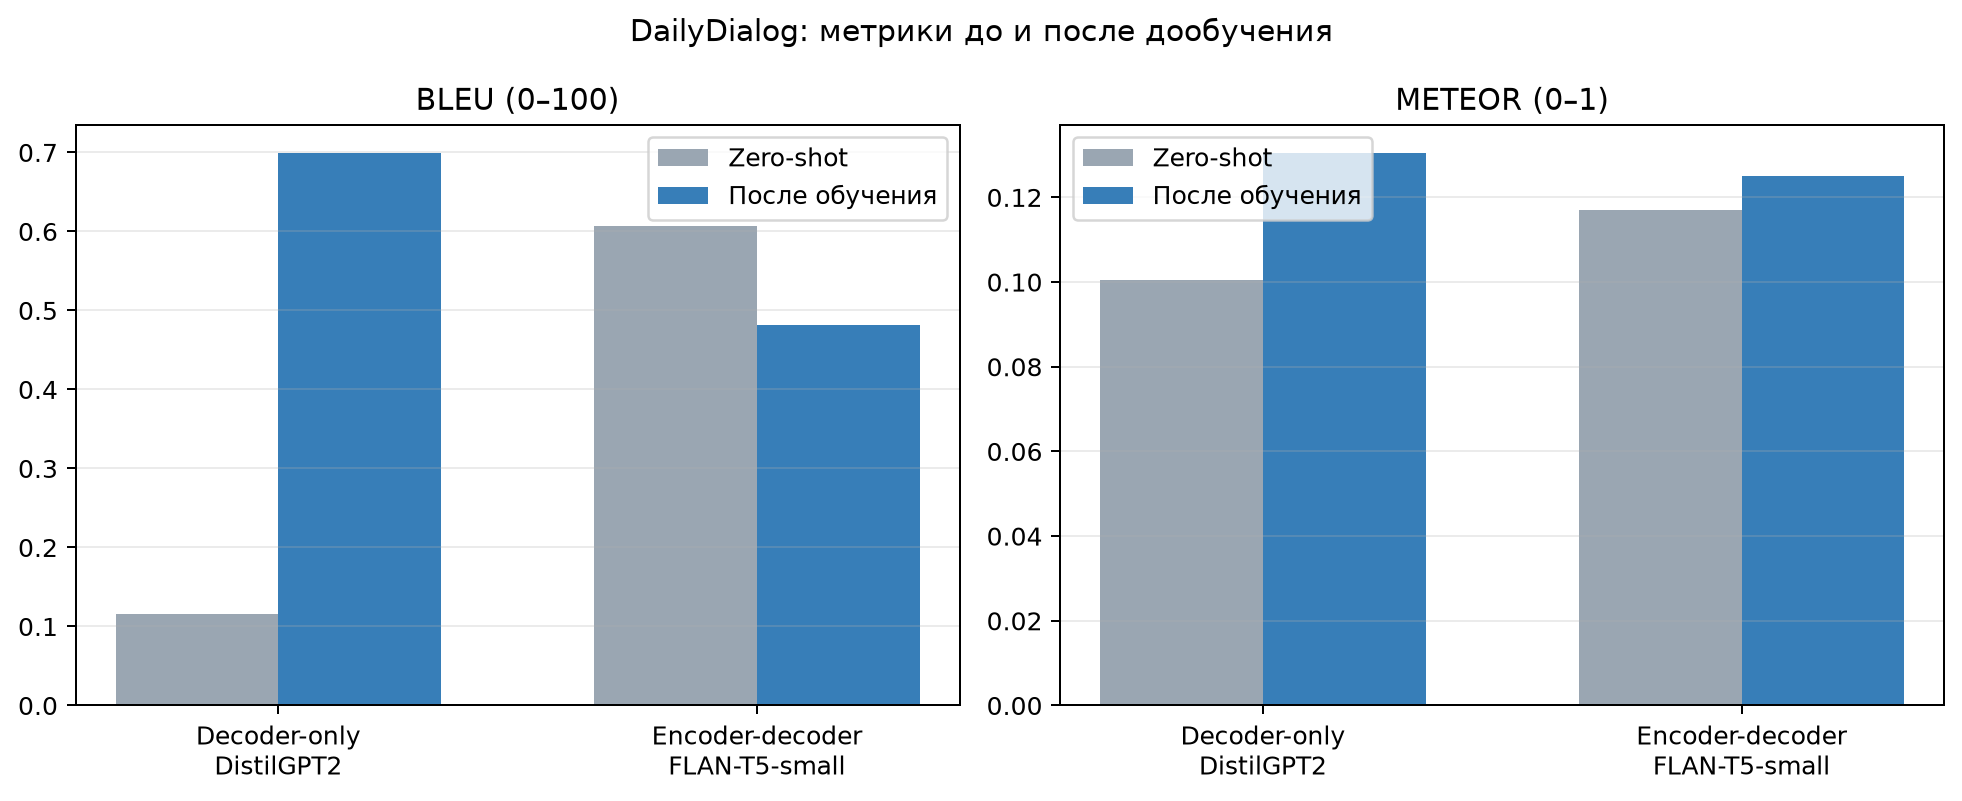

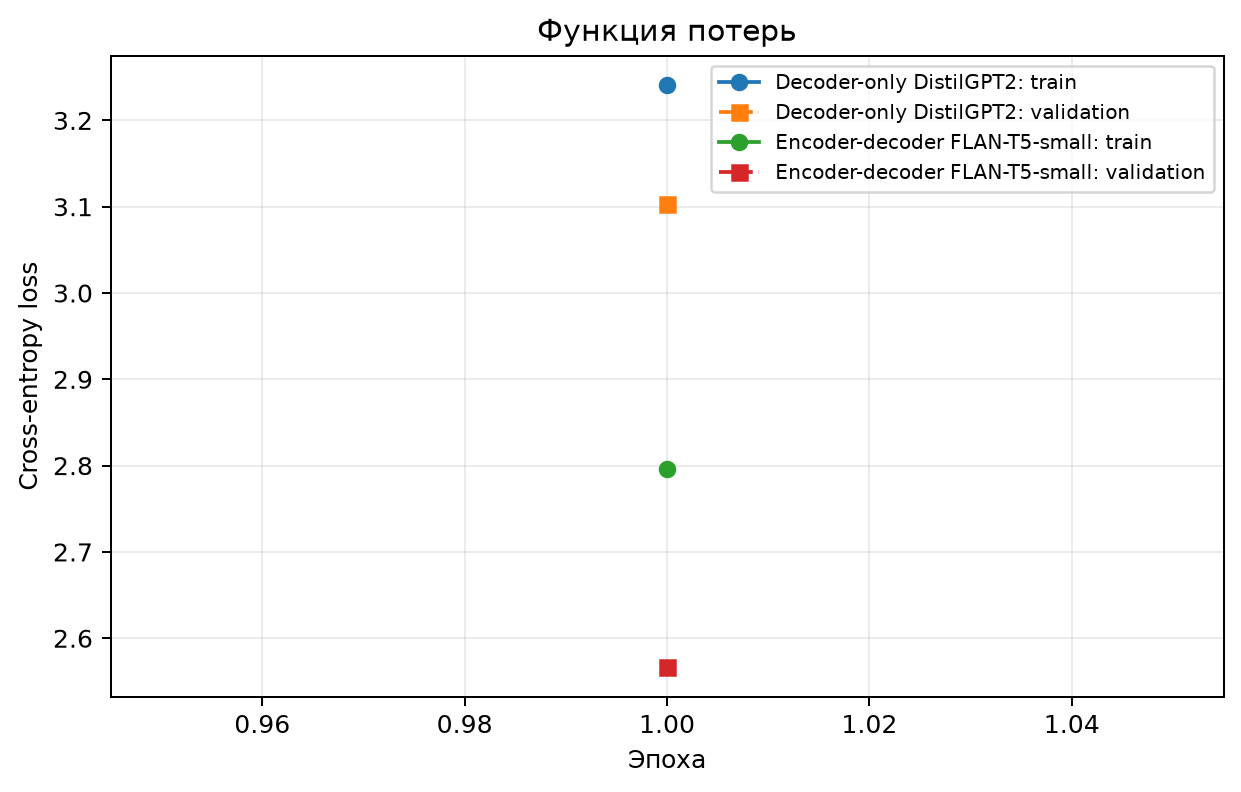

In [13]:
from IPython.display import Image, display

results_path = LAB_ROOT / "artifacts" / "results.json"
results = json.loads(results_path.read_text(encoding="utf-8"))

rows = []
for architecture in ["decoder-only", "encoder-decoder"]:
    for stage in ["zero_shot", "fine_tuned"]:
        metrics = results[architecture][stage]
        rows.append({
            "architecture": architecture,
            "stage": stage,
            "BLEU": metrics["bleu"],
            "METEOR": metrics["meteor"],
        })

display(pd.DataFrame(rows))
display(Image(filename=str(LAB_ROOT / "artifacts" / "metrics_comparison.png")))
display(Image(filename=str(LAB_ROOT / "artifacts" / "training_loss.png")))

## Вывод

Дообучение улучшает соответствие ответа эталонной реплике. BLEU сильнее реагирует на совпадение слов и коротких фраз, а METEOR дополнительно учитывает близкие формы слов. Сравнивать архитектуры нужно по таблице и примерам сгенерированных ответов.